# WordCount: Hadoop MapReduce vs Spark on Databricks
**Author:** Miguel Narváez

This Notebook tries to reproduce in Databricks, with PySpark and Spark SQL, the WordCount analysis previously run on a Hadoop 3.5.0 cluster, verify that both results are identical, and compare their execution times.

**Dataset:** *Annex 1 - Aplication.txt* from the virtual campus` (300 lines, 296 words, 10 distinct words).

In [0]:
%sql
-- Catalog: top-level container for this lab (Unity Catalog)
CREATE CATALOG IF NOT EXISTS miguel_narvaez_lab
COMMENT 'Big Data lab - WordCount: Hadoop vs Spark (Miguel Narvaez)';

In [0]:
%sql
-- Clean start: drop the schema with all its tables and the volume, then recreate it below
DROP SCHEMA IF EXISTS miguel_narvaez_lab.wordcount CASCADE;

In [0]:
%sql
-- Schema: groups the Bronze, Silver and Gold tables of the medallion architecture
CREATE SCHEMA IF NOT EXISTS miguel_narvaez_lab.wordcount
COMMENT 'Medallion architecture tables for the WordCount analysis';

-- Volume: storage for the raw input files uploaded from the virtual campus
CREATE VOLUME IF NOT EXISTS miguel_narvaez_lab.wordcount.raw_files
COMMENT 'Raw files: annex1.txt and the Hadoop WordCount output';

In [0]:
%sql
SHOW VOLUMES IN miguel_narvaez_lab.wordcount;

database,volume_name
wordcount,raw_files


## 1. Setup
Paths, catalog context and a helper to measure execution times.

In [0]:
import time
from pyspark.sql import functions as F

# Unity Catalog location created in the previous cells
CATALOG = "miguel_narvaez_lab"
SCHEMA = "wordcount"
VOLUME_PATH = f"/Volumes/{CATALOG}/{SCHEMA}/raw_files"

# Input files in the volume
ANNEX_PATH = f"{VOLUME_PATH}/annex1.txt"
HADOOP_OUTPUT_PATH = f"{VOLUME_PATH}/hadoop_wordcount_output.txt"

# Work inside our catalog and schema, so tables can be named without prefixes
spark.sql(f"USE CATALOG {CATALOG}")
spark.sql(f"USE SCHEMA {SCHEMA}")

# Timing helper: runs an action several times and stores each duration
timings = []


def timed(label, fn, runs=5):
    # Execute the specified Spark workload multiple times
    # and record the execution time of each run.
    for i in range(1, runs + 1):

        # Start the high-resolution timer
        start = time.perf_counter()

        # Execute the workload (A Spark action)
        fn()

        # Compute elapsed execution time in seconds
        elapsed = time.perf_counter() - start

        # Store timing information for later analysis
        timings.append(
            {
                "engine": "Spark",
                "variant": label,
                "run": i,
                "seconds": round(elapsed, 3),
            }
        )

        # Display the execution time for the current run
        print(f"{label} | run {i}: {elapsed:.3f} s")

In [0]:
import urllib.request
import urllib.parse

# GitHub repository that stores the input files
GITHUB_USER = "mignarvaez"
GITHUB_REPO = "hadoop-spark-databricks-etl-lab"
BRANCH = "main"
RAW_BASE = (
    f"https://raw.githubusercontent.com/{GITHUB_USER}/{GITHUB_REPO}/{BRANCH}/resources"
)

# File name in the repo -> file name in the raw volume
files = {
    "Annex 1 - Aplication.txt": "annex1.txt",
    "hadoop_wordcount_output.txt": "hadoop_wordcount_output.txt",
}

for repo_name, volume_name in files.items():
    url = (
        f"{RAW_BASE}/{urllib.parse.quote(repo_name)}"  # encodes the spaces in the name
    )
    with urllib.request.urlopen(url) as response:
        data = response.read()
    with open(
        f"{VOLUME_PATH}/{volume_name}", "wb"
    ) as f:  # write the file into the volume
        f.write(data)
    print(f"{repo_name} -> {VOLUME_PATH}/{volume_name} ({len(data)} bytes)")

# Check that both files are now in the volume
display(dbutils.fs.ls(VOLUME_PATH))

Annex 1 - Aplication.txt -> /Volumes/miguel_narvaez_lab/wordcount/raw_files/annex1.txt (2860 bytes)
hadoop_wordcount_output.txt -> /Volumes/miguel_narvaez_lab/wordcount/raw_files/hadoop_wordcount_output.txt (129 bytes)


path,name,size,modificationTime
dbfs:/Volumes/miguel_narvaez_lab/wordcount/raw_files/annex1.txt,annex1.txt,2860,1794349162000
dbfs:/Volumes/miguel_narvaez_lab/wordcount/raw_files/hadoop_wordcount_output.txt,hadoop_wordcount_output.txt,129,1794349162000


## 2. Bronze layer (Extract)
Raw data ingested as-is, plus ingestion metadata.
Hadoop equivalent: the input file stored in HDFS.

In [0]:
# Read the raw text file: one row per line, in a single column called "value"
bronze_annex_lines = (
    spark.read.text(ANNEX_PATH)
    .withColumn("source_file", F.col("_metadata.file_path"))  # where the row came from
    .withColumn("ingested_at", F.current_timestamp())  # when it was ingested
)

# Save it unchanged as a Delta table (overwrite makes the cell re-runnable)
(
    bronze_annex_lines.write.mode("overwrite")
    .option("overwriteSchema", "true")
    .saveAsTable("bronze_annex_lines")
)

display(spark.table("bronze_annex_lines").limit(10))

value,source_file,ingested_at
Speech,dbfs:/Volumes/miguel_narvaez_lab/wordcount/raw_files/annex1.txt,2026-11-10T22:19:30.147Z
Processing,dbfs:/Volumes/miguel_narvaez_lab/wordcount/raw_files/annex1.txt,2026-11-10T22:19:30.147Z
Assistants,dbfs:/Volumes/miguel_narvaez_lab/wordcount/raw_files/annex1.txt,2026-11-10T22:19:30.147Z
Assistants,dbfs:/Volumes/miguel_narvaez_lab/wordcount/raw_files/annex1.txt,2026-11-10T22:19:30.147Z
Vision,dbfs:/Volumes/miguel_narvaez_lab/wordcount/raw_files/annex1.txt,2026-11-10T22:19:30.147Z
Predictive,dbfs:/Volumes/miguel_narvaez_lab/wordcount/raw_files/annex1.txt,2026-11-10T22:19:30.147Z
Vision,dbfs:/Volumes/miguel_narvaez_lab/wordcount/raw_files/annex1.txt,2026-11-10T22:19:30.147Z
Assistants,dbfs:/Volumes/miguel_narvaez_lab/wordcount/raw_files/annex1.txt,2026-11-10T22:19:30.147Z
Vision,dbfs:/Volumes/miguel_narvaez_lab/wordcount/raw_files/annex1.txt,2026-11-10T22:19:30.147Z
Predictive,dbfs:/Volumes/miguel_narvaez_lab/wordcount/raw_files/annex1.txt,2026-11-10T22:19:30.147Z


In [0]:
# Hadoop output: "word<TAB>count" per line, read with an explicit schema
bronze_hadoop_output = (
    spark.read.option("sep", "\t")
    # Word is String and hadoop_count is INT
    .schema("word STRING, hadoop_count INT")
    .csv(HADOOP_OUTPUT_PATH)
    .withColumn("source_file", F.col("_metadata.file_path"))
    .withColumn("ingested_at", F.current_timestamp())
)

(
    bronze_hadoop_output.write.mode("overwrite")
    .option("overwriteSchema", "true")
    .saveAsTable("bronze_hadoop_output")
)

display(spark.table("bronze_hadoop_output"))

word,hadoop_count,source_file,ingested_at
Assistants,62,dbfs:/Volumes/miguel_narvaez_lab/wordcount/raw_files/hadoop_wordcount_output.txt,2026-11-10T22:19:43.477Z
Automation,2,dbfs:/Volumes/miguel_narvaez_lab/wordcount/raw_files/hadoop_wordcount_output.txt,2026-11-10T22:19:43.477Z
Learning,5,dbfs:/Volumes/miguel_narvaez_lab/wordcount/raw_files/hadoop_wordcount_output.txt,2026-11-10T22:19:43.477Z
Predictive,54,dbfs:/Volumes/miguel_narvaez_lab/wordcount/raw_files/hadoop_wordcount_output.txt,2026-11-10T22:19:43.477Z
Processing,8,dbfs:/Volumes/miguel_narvaez_lab/wordcount/raw_files/hadoop_wordcount_output.txt,2026-11-10T22:19:43.477Z
Recognition,4,dbfs:/Volumes/miguel_narvaez_lab/wordcount/raw_files/hadoop_wordcount_output.txt,2026-11-10T22:19:43.477Z
Recommendation,16,dbfs:/Volumes/miguel_narvaez_lab/wordcount/raw_files/hadoop_wordcount_output.txt,2026-11-10T22:19:43.477Z
Robotics,61,dbfs:/Volumes/miguel_narvaez_lab/wordcount/raw_files/hadoop_wordcount_output.txt,2026-11-10T22:19:43.477Z
Speech,18,dbfs:/Volumes/miguel_narvaez_lab/wordcount/raw_files/hadoop_wordcount_output.txt,2026-11-10T22:19:43.477Z
Vision,66,dbfs:/Volumes/miguel_narvaez_lab/wordcount/raw_files/hadoop_wordcount_output.txt,2026-11-10T22:19:43.477Z


In [0]:
%sql
-- Raw profile of the annex: total lines and empty lines
SELECT
  COUNT(*) AS total_lines,
  SUM(
    CASE
      WHEN trim(value) = '' THEN 1
      ELSE 0
    END
  ) AS empty_lines,
  SUM(
    CASE
      WHEN trim(value) <> '' THEN 1
      ELSE 0
    END
  ) AS non_empty_lines
FROM
  bronze_annex_lines;

total_lines,empty_lines,non_empty_lines
300,4,296


## 3. Silver layer (Transform)
Cleaned data: one valid word per row, ready for analysis.

This layer reproduces the **Map phase** of Hadoop's WordCount. According to the official MapReduce page, the **TokenizerMapper** processes one line at a time, splits it into tokens separated by whitespace with **StringTokenizer**, and emits a key-value pair **<word, 1>** for each token (Apache Software Foundation, s. f.).
- Hadoop: **TokenizerMappe** -> **context.write(word, one)**
- Spark: **split + explode** produce one row per word, and the column *one* holds the value *1*

Words are **not** lower-cased, so the result stays identical to Hadoop's case-sensitive WordCount.

In [0]:
silver_annex_words = (
    spark.table("bronze_annex_lines")
    # Remove Windows carriage returns (CRLF) and surrounding spaces
    .withColumn("clean_line", F.trim(F.regexp_replace("value", "\r", "")))
    # Drop empty lines: they contain no words
    .filter(F.col("clean_line") != "")
    # Map phase: split each line on whitespace and emit one row per word
    .withColumn("word", F.explode(F.split("clean_line", r"\s+")))
    # The 1 that Hadoop's mapper puts for each word
    .withColumn("one", F.lit(1))
    # Extra numeric attribute for the SQL analysis
    .withColumn("word_length", F.length("word"))
    .withColumn("processed_at", F.current_timestamp())
    .select("word", "one", "word_length", "source_file", "processed_at")
)

(
    silver_annex_words.write.mode("overwrite")
    .option("overwriteSchema", "true")
    .saveAsTable("silver_annex_words")
)

display(spark.table("silver_annex_words").limit(10))

word,one,word_length,source_file,processed_at
Speech,1,6,dbfs:/Volumes/miguel_narvaez_lab/wordcount/raw_files/annex1.txt,2026-11-10T22:19:51.154Z
Processing,1,10,dbfs:/Volumes/miguel_narvaez_lab/wordcount/raw_files/annex1.txt,2026-11-10T22:19:51.154Z
Assistants,1,10,dbfs:/Volumes/miguel_narvaez_lab/wordcount/raw_files/annex1.txt,2026-11-10T22:19:51.154Z
Assistants,1,10,dbfs:/Volumes/miguel_narvaez_lab/wordcount/raw_files/annex1.txt,2026-11-10T22:19:51.154Z
Vision,1,6,dbfs:/Volumes/miguel_narvaez_lab/wordcount/raw_files/annex1.txt,2026-11-10T22:19:51.154Z
Predictive,1,10,dbfs:/Volumes/miguel_narvaez_lab/wordcount/raw_files/annex1.txt,2026-11-10T22:19:51.154Z
Vision,1,6,dbfs:/Volumes/miguel_narvaez_lab/wordcount/raw_files/annex1.txt,2026-11-10T22:19:51.154Z
Assistants,1,10,dbfs:/Volumes/miguel_narvaez_lab/wordcount/raw_files/annex1.txt,2026-11-10T22:19:51.154Z
Vision,1,6,dbfs:/Volumes/miguel_narvaez_lab/wordcount/raw_files/annex1.txt,2026-11-10T22:19:51.154Z
Predictive,1,10,dbfs:/Volumes/miguel_narvaez_lab/wordcount/raw_files/annex1.txt,2026-11-10T22:19:51.154Z


In [0]:
%sql
-- Silver profile: every row is one word
SELECT
  COUNT(*) AS total_words,
  COUNT(DISTINCT word) AS distinct_words,
  SUM(one) AS sum_of_ones,
  MIN(word_length) AS min_length,
  MAX(word_length) AS max_length
FROM
  silver_annex_words;

total_words,distinct_words,sum_of_ones,min_length,max_length
296,10,296,6,14


## 4. Gold layer (Load)
Aggregated, analysis-ready data: one row per word with its total count.

This layer reproduces the **Reduce phase** of Hadoop's WordCount. In the official MapReduce tutorial, the **IntSumReducer** receives each word together with all its **1** values and simply sums them, producing the number of occurrences of each word (Apache Software Foundation, n.d).
- Hadoop: **IntSumReducer** -> **sum += val.get()** -> **context.write(key, result)**
- Spark: **groupBy("word")** + **sum("one")**

In [0]:
gold_word_counts = (
    spark.table("silver_annex_words")
    # Reduce phase: group all (word, 1) pairs by word and add up the ones
    .groupBy("word")
    .agg(F.sum("one").alias("word_count"), F.first("word_length").alias("word_length"))
    .withColumn("loaded_at", F.current_timestamp())
)

(
    gold_word_counts.write.mode("overwrite")
    .option("overwriteSchema", "true")
    .saveAsTable("gold_word_counts")
)

display(spark.table("gold_word_counts").orderBy(F.desc("word_count")))

word,word_count,word_length,loaded_at
Vision,66,6,2026-11-10T22:19:58.788Z
Assistants,62,10,2026-11-10T22:19:58.788Z
Robotics,61,8,2026-11-10T22:19:58.788Z
Predictive,54,10,2026-11-10T22:19:58.788Z
Speech,18,6,2026-11-10T22:19:58.788Z
Recommendation,16,14,2026-11-10T22:19:58.788Z
Processing,8,10,2026-11-10T22:19:58.788Z
Learning,5,8,2026-11-10T22:19:58.788Z
Recognition,4,11,2026-11-10T22:19:58.788Z
Automation,2,10,2026-11-10T22:19:58.788Z


In [0]:
# Physical plan of the Reduce phase: shows how Spark will run the aggregation
# (read the Silver table, then group by word and sum the ones)
(
    spark.table("silver_annex_words")
    .groupBy("word")
    .agg(F.sum("one").alias("word_count"))
    .explain()
)

== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- == Initial Plan ==
   PhotonResultStage
   +- PhotonColumnarToRow
      +- PhotonGroupingAgg(keys=[word#12075], functions=[sum(one#12076)])
         +- PhotonScan parquet miguel_narvaez_lab.wordcount.silver_annex_words[word#12075,one#12076] DataFilters: [], DictionaryFilters: [], Format: parquet, Location: PreparedDeltaFileIndex(1 paths)[s3://dbstorage-prod-rhhad/uc/890ba4d6-4935-44b8-96cd-246993f30550..., OptionalDataFilters: [], PartitionFilters: [], ReadSchema: struct<word:string,one:int>, RequiredDataFilters: []


== Photon Explanation ==
The query is fully supported by Photon.
== Optimizer Statistics (table names per statistics state) ==
  missing = 
  partial = 
  full    = silver_annex_words



### Reading the physical plan
*explain()* shows how Spark plans to run the Reduce(silver) phase

1. **PhotonScan parquet ... silver_annex_words**: reads the Silver table. Only the two columns needed (**word** and **one**) are loaded.
2. **PhotonGroupingAgg(keys=[word], functions=[sum(one)])**: the Reduce phase itself. Groups by word and sums the ones.
3. **PhotonColumnarToRow / PhotonResultStage**: returns the result.

**Photon** is Databricks' execution engine, Spark still plans the query, but Photon runs it, processing data in column batches instead of row by row. It is always enabled on serverless compute (Databricks, 2026). The line *"fully supported by Photon"* confirms the whole query ran on it There is no shuffle step (**Exchange**) in the plan. The data is so small that, most likely, it fits in a single partition, so Spark aggregates it in one step. Hadoop, instead, always runs map and reduce as separate tasks with a shuffle in between, even for a file this small.

In [0]:
%sql
-- Gold profile: one row per word, and the counts must add up to the Silver total
SELECT
  COUNT(*) AS distinct_words,
  SUM(word_count) AS total_words,
  MAX(word_count) AS max_count,
  MIN(word_count) AS min_count
FROM
  gold_word_counts;

distinct_words,total_words,max_count,min_count
10,296,66,2


## 5. Spark SQL queries
The Gold table is analyzed with SQL queries: ranking, totals, percentages, words above average and word length versus frequency.

In [0]:
%sql
-- Q1. Words ranked by frequency
SELECT
  -- Ranks words from most to least frequent, assigning the same rank to ties
  RANK() OVER (ORDER BY word_count DESC) AS rank,
  word,
  word_count
FROM
  gold_word_counts
ORDER BY
  rank;

rank,word,word_count
1,Vision,66
2,Assistants,62
3,Robotics,61
4,Predictive,54
5,Speech,18
6,Recommendation,16
7,Processing,8
8,Learning,5
9,Recognition,4
10,Automation,2


In [0]:
%sql
-- Q2. Overall totals
SELECT
  SUM(word_count) AS total_words,
  COUNT(*) AS distinct_words,
  -- Calculates the average frequency of all words
  ROUND(AVG(word_count), 2) AS avg_count_per_word,
  -- Returns the word associated with the highest count
  MAX_BY(word, word_count) AS most_frequent_word,
  -- Returns the word associated with the lowest count
  MIN_BY(word, word_count) AS least_frequent_word
FROM
  gold_word_counts;

total_words,distinct_words,avg_count_per_word,most_frequent_word,least_frequent_word
296,10,29.6,Vision,Automation


In [0]:
%sql
-- Q3. Share of each word over the total, and cumulative share
SELECT
  word,
  word_count,
  -- Calculates each word's percentage contribution to the total count
  ROUND(100.0 * word_count / SUM(word_count) OVER (), 2) AS pct_of_total,
  -- Calculates the cumulative percentage when words are sorted by count in descending order
  ROUND(
    100.0
      * SUM(word_count) OVER (
          ORDER BY word_count DESC
          -- Includes all rows from the beginning of the ordered window up to the current row,
          -- so each calculation accumulates values progressively.
          ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW
        )
      / SUM(word_count) OVER (),
    2
  ) AS cumulative_pct
FROM
  gold_word_counts
ORDER BY
  word_count DESC;

word,word_count,pct_of_total,cumulative_pct
Vision,66,22.30,22.30
Assistants,62,20.95,43.24
Robotics,61,20.61,63.85
Predictive,54,18.24,82.09
Speech,18,6.08,88.18
Recommendation,16,5.41,93.58
Processing,8,2.70,96.28
Learning,5,1.69,97.97
Recognition,4,1.35,99.32
Automation,2,0.68,100.00


In [0]:
%sql
-- Q4. Words that appear more often than the average word
SELECT
  word,
  word_count
FROM
  gold_word_counts
WHERE
  word_count > (SELECT AVG(word_count) FROM gold_word_counts)
ORDER BY
  word_count DESC;

word,word_count
Vision,66
Assistants,62
Robotics,61
Predictive,54


In [0]:
%sql
-- Q5. Numeric analysis: how word length relates to frequency
SELECT
  word_length,
  COUNT(*) AS distinct_words,
  SUM(word_count) AS occurrences,
  -- COLLECT_LIST gathers words into an array, and CONCAT_WS joins them into a comma-separated string.
  CONCAT_WS(', ', COLLECT_LIST(word)) AS words
FROM
  gold_word_counts
GROUP BY
  word_length
ORDER BY
  word_length;

word_length,distinct_words,occurrences,words
6,2,84,"Speech, Vision"
8,2,66,"Robotics, Learning"
10,4,126,"Predictive, Assistants, Automation, Processing"
11,1,4,Recognition
14,1,16,Recommendation


## 6. Comparison against Hadoop
The Spark result (Gold) is compared word by word with the output produced by Hadoop's WordCount (**part-r-00000**, loaded in Bronze).
A **FULL OUTER JOIN** keeps words that might appear in only one of the two results, so any difference would be visible.

In [0]:
%sql
-- Word-by-word comparison: Spark (Gold) vs Hadoop (Bronze copy of part-r-00000)
CREATE OR REPLACE TABLE gold_hadoop_verification AS
SELECT
  COALESCE(s.word, h.word) AS word,
  s.word_count AS spark_count,
  h.hadoop_count AS hadoop_count,
  CASE
    WHEN s.word_count = h.hadoop_count THEN 'YES'
    ELSE 'NO'
  END AS match
FROM
  gold_word_counts s
    FULL OUTER JOIN bronze_hadoop_output h
      ON s.word = h.word;

SELECT
  *
FROM
  gold_hadoop_verification
ORDER BY
  spark_count DESC;

word,spark_count,hadoop_count,match
Vision,66,66,YES
Assistants,62,62,YES
Robotics,61,61,YES
Predictive,54,54,YES
Speech,18,18,YES
Recommendation,16,16,YES
Processing,8,8,YES
Learning,5,5,YES
Recognition,4,4,YES
Automation,2,2,YES


In [0]:
%sql
-- Verification summary
SELECT
  COUNT(*) AS words_compared,
  SUM(
    CASE
      WHEN match = 'YES' THEN 1
      ELSE 0
    END
  ) AS words_matching,
  SUM(spark_count) AS spark_total,
  SUM(hadoop_count) AS hadoop_total,
  CASE
    WHEN
      SUM(
        CASE
          WHEN match = 'NO' THEN 1
          ELSE 0
        END
      ) = 0
    THEN
      'Spark and Hadoop results are identical'
    ELSE 'Differences found'
  END AS verification
FROM
  gold_hadoop_verification;

words_compared,words_matching,spark_total,hadoop_total,verification
10,10,296,296,Spark and Hadoop results are identical


## 7. Execution time comparison

**Note:** Spark times are measured live every time this notebook runs, so they will vary slightly between executions.  
*Spark measurement corresponds to the execution performed on November 10, 2026, at 5:18 PM*

Spark is timed with the same kind of work Hadoop did: **read -> process -> write** the result.
Three Spark variants are measured, each 5 times after one warm-up run (not recorded):
- **Spark end-to-end:** read the file, build Bronze -> Silver -> Gold and write the three Delta tables (comparable to Hadoop, which reads from and writes to HDFS).
- **Spark compute only:** read, transform and count returning the result with **collect()** (no writes).
- **Spark SQL query:** the aggregation as a SQL query over the Silver table.

Spark transformations are *lazy*: they are not computed right away, only when an action needs a result (Apache Spark, s. f.). That is why every timed function ends with an action (*write* or *collect*); otherwise the timer would measure nothing.

The Hadoop times were measured in the cluster with *time* (end-to-end) and the job time inside YARN.

In [0]:
# Start from a clean list so the cell can be re-run
timings.clear()

def spark_end_to_end():
    # Bronze: raw lines
    spark.read.text(ANNEX_PATH).write.mode("overwrite").saveAsTable("timing_bronze")
    # Silver layer: clean text, split lines into individual words, and assign a value of 
    # 1 to each word occurrence (Map phase).
    (
        spark.table("timing_bronze")
        .withColumn("clean_line", F.trim(F.regexp_replace("value", "\r", "")))
        .filter(F.col("clean_line") != "")
        .withColumn("word", F.explode(F.split("clean_line", r"\s+")))
        .withColumn("one", F.lit(1))
        .select("word", "one")
        .write.mode("overwrite")
        .saveAsTable("timing_silver")
    )
    # Gold layer: aggregate word occurrences and generate the final word frequency table (Reduce phase).
    (
        spark.table("timing_silver")
        .groupBy("word")
        .agg(F.sum("one").alias("word_count"))
        .write.mode("overwrite")
        .saveAsTable("timing_gold")
    )

def spark_compute_only():
    # Execute the complete word-count computation in memory without 
    # persisting intermediate or final results.
    (
        spark.read.text(ANNEX_PATH)
        .withColumn("clean_line", F.trim(F.regexp_replace("value", "\r", "")))
        .filter(F.col("clean_line") != "")
        .withColumn("word", F.explode(F.split("clean_line", r"\s+")))
        .groupBy("word")
        .count()
        .collect()
    )

def spark_sql_query():
    # Execute the aggregation using Spark SQL on the Silver table and 
    # return the word frequencies.
    spark.sql("""
        SELECT word, SUM(one) AS word_count
        FROM silver_annex_words
        GROUP BY word
    """).collect()

variants = [
    ("Spark end-to-end (Bronze-Silver-Gold)", spark_end_to_end),
    ("Spark compute only (collect)", spark_compute_only),
    ("Spark SQL query", spark_sql_query),
]

for label, fn in variants:
    fn()  # warm-up run, not recorded
    timed(label, fn, runs=5)

# Clean up the temporary tables used only for timing
for t in ["timing_bronze", "timing_silver", "timing_gold"]:
    spark.sql(f"DROP TABLE IF EXISTS {t}")

Spark end-to-end (Bronze-Silver-Gold) | run 1: 7.014 s
Spark end-to-end (Bronze-Silver-Gold) | run 2: 6.160 s
Spark end-to-end (Bronze-Silver-Gold) | run 3: 6.069 s
Spark end-to-end (Bronze-Silver-Gold) | run 4: 6.119 s
Spark end-to-end (Bronze-Silver-Gold) | run 5: 6.415 s
Spark compute only (collect) | run 1: 0.739 s
Spark compute only (collect) | run 2: 0.786 s
Spark compute only (collect) | run 3: 0.674 s
Spark compute only (collect) | run 4: 0.726 s
Spark compute only (collect) | run 5: 0.693 s
Spark SQL query | run 1: 0.920 s
Spark SQL query | run 2: 1.021 s
Spark SQL query | run 3: 0.667 s
Spark SQL query | run 4: 0.732 s
Spark SQL query | run 5: 0.718 s


### Hadoop baseline: WordCount
Hadoop's WordCount example was run on *annex1.txt* in a Hadoop 3.5.0 cluster of one master and three workers (VirtualBox VMs, 1.75 GB RAM per worker). The job was repeated until five successful runs were obtained, which took six attempts. For each run, two times were recorded:
- **End-to-end:** measured with **time hadoop jar ...** (the **real** value), including the client JVM start and job submission.
- **Job in YARN:** **Finish-Time** minus **Start-Time** from **yarn application -status <application_id>**.

| Run | Application ID | End-to-end (s) | Job in YARN (s) | Task retries |
|---|---|---|---|---|
| 1 | application_1794327535721_0002 | 141.764 | 136.96 | 2 |
| 2 | application_1794327535721_0003 | 48.184 | 43.10 | 2 |
| 3 | application_1794327535721_0005 | 33.883 | 29.15 | 1 |
| 4 | application_1794327535721_0006 | 61.101 | 56.06 | 3 |
| 5 | application_1794327535721_0007 | 47.774 | 43.48 | 2 |

One additional attempt failed after its tasks reached Hadoop's retry limit. Every successful run needed task retries, most likely because of the workers' limited memory; run 1 was especially slow (141.8 s).

Median end-to-end time **48.2 s**, median job time in YARN **43.5 s**. The constant gap of about 4.8 s is the client start-up and job submission.

In [0]:
# Hadoop times measured in the cluster (5 successful runs out of 6 attempts)
hadoop_runs = [
    # run, end-to-end (time real), job time in YARN (Finish-Time - Start-Time), task retries
    (1, 141.764, 136.96, 2),
    (2,  48.184,  43.10, 2),
    (3,  33.883,  29.15, 1),
    (4,  61.101,  56.06, 3),
    (5,  47.774,  43.48, 2),
]

for run, real_s, elapsed_s, retries in hadoop_runs:
    timings.append(
        {
            "engine": "Hadoop",
            "variant": "Hadoop end-to-end (time real)",
            "run": run,
            "seconds": real_s,
        }
    )
    timings.append(
        {
            "engine": "Hadoop",
            "variant": "Hadoop job in YARN (elapsedTime)",
            "run": run,
            "seconds": elapsed_s,
        }
    )

# Save all measurements as a Gold table
(
    spark.createDataFrame(timings)
    .select("engine", "variant", "run", "seconds")
    .write.mode("overwrite")
    .option("overwriteSchema", "true")
    .saveAsTable("gold_execution_times")
)

display(spark.table("gold_execution_times").orderBy("engine", "variant", "run"))

engine,variant,run,seconds
Hadoop,Hadoop end-to-end (time real),1,141.764
Hadoop,Hadoop end-to-end (time real),2,48.184
Hadoop,Hadoop end-to-end (time real),3,33.883
Hadoop,Hadoop end-to-end (time real),4,61.101
Hadoop,Hadoop end-to-end (time real),5,47.774
Hadoop,Hadoop job in YARN (elapsedTime),1,136.96
Hadoop,Hadoop job in YARN (elapsedTime),2,43.1
Hadoop,Hadoop job in YARN (elapsedTime),3,29.15
Hadoop,Hadoop job in YARN (elapsedTime),4,56.06
Hadoop,Hadoop job in YARN (elapsedTime),5,43.48


In [0]:
%sql
-- Summary per engine and variant (median is robust to slow runs with retries)
SELECT
  engine,
  variant,
  COUNT(*) AS runs,
  ROUND(MIN(seconds), 3) AS min_s,
  ROUND(MEDIAN(seconds), 3) AS median_s,
  ROUND(MAX(seconds), 3) AS max_s
FROM
  gold_execution_times
GROUP BY
  engine,
  variant
ORDER BY
  median_s DESC;

engine,variant,runs,min_s,median_s,max_s
Hadoop,Hadoop end-to-end (time real),5,33.883,48.184,141.764
Hadoop,Hadoop job in YARN (elapsedTime),5,29.15,43.48,136.96
Spark,Spark end-to-end (Bronze-Silver-Gold),5,6.069,6.16,7.014
Spark,Spark SQL query,5,0.667,0.732,1.021
Spark,Spark compute only (collect),5,0.674,0.726,0.786


*Spark measurement corresponds to the execution performed on November 10, 2026, at 5:18 PM*

The table shows a clear gap between both engines: Hadoop needed a median of **48.2 s** end-to-end, while Spark completed the same read-process-write pipeline in **6.16 s**, and only about **0.73 s** when just counting the words (DataFrame or SQL). Hadoop's wide range comes from the task retries in every run.

The following chart compares the median time of each variant. A logarithmic scale is used so that Hadoop's and Spark's times, which differ by orders of magnitude, can be seen in the same plot.

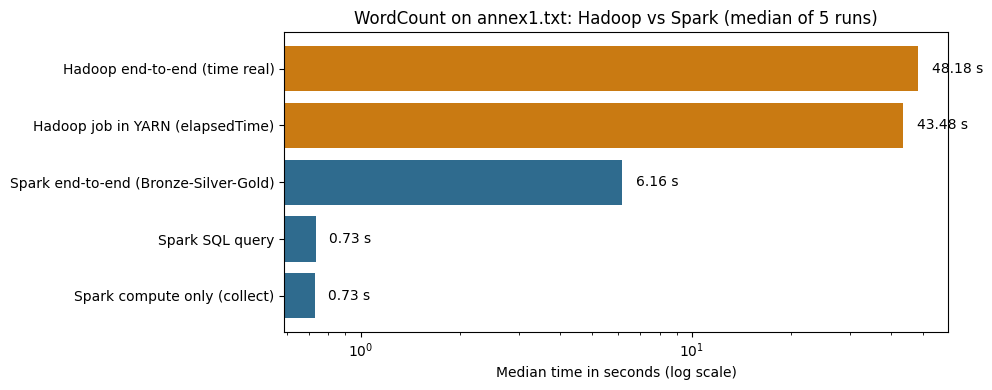

In [0]:
import matplotlib.pyplot as plt

# Retrieve the median execution time for each implementation variant.
summary = spark.sql("""
    SELECT variant, MEDIAN(seconds) AS median_s
    FROM gold_execution_times
    GROUP BY variant
    ORDER BY median_s
""").toPandas()

# Assign colors by engine
colors = ["#2F6B8E" if v.startswith("Spark") else "#C97A12" for v in summary["variant"]]

# Create a horizontal bar chart to compare median execution times.
fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.barh(summary["variant"], summary["median_s"], color=colors)

# Use a logarithmic scale because execution times differ by orders of magnitude.
ax.set_xscale("log")

# Configure axis label and chart title
ax.set_xlabel("Median time in seconds (log scale)")
ax.set_title("WordCount on annex1.txt: Hadoop vs Spark (median of 5 runs)")

# Display the median execution time next to each bar
for bar, value in zip(bars, summary["median_s"]):
    ax.text(
        value * 1.1,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.2f} s",
        va="center"
    )

# Adjust spacing
plt.tight_layout()
plt.show()

### Results
*Spark measurement corresponds to the execution performed on November 10, 2026, at 5:18 PM*
| Comparison | Hadoop | Spark |
|---|---|---|
| End-to-end, median (read, process and write) | 48.2 s | 6.16 s |
| End-to-end, best run (minimum) | 33.9 s | 6.07 s |
| Processing only (Spark compute / SQL), median | — | 0.73 s |

- Spark was about 8 times faster end-to-end (median), and about 6 times faster even against Hadoop's best run.
- Hadoop's time is mostly overhead, not computation. For a 296-word file, each run had to start a client JVM, launch an ApplicationMaster and separate containers for map and reduce in YARN, and write intermediate results to disk for the shuffle. Task retries, most likely caused by the workers' limited memory, added time to every run; run 1 took almost three times the median (141.8 s).
- In Spark, writing is the expensive part. Counting the words took about 0.7 s, while the end-to-end run took about 6.1 s, so about 5.4 s went into writing the three Delta tables (Bronze, Silver, Gold).
- SQL and DataFrame code perform the same (about 0.73 s each), wich is expected because both go through the same optimizer and execution engine.
- The hardware is not comparable: three small VirtualBox VMs versus Databricks' serverless cloud compute.
- The dataset is tiny, so both engines are measuring fixed start-up and scheduling costs more than processing speed. Databricks itself notes that queries finishing in under two seconds are dominated by planning and scheduling rather than data processing 
- The result is only a comparison of architectures

## 8. Visualization and summary
Word frequencies from the Gold table, followed by a one-table summary of the whole analysis: results, verification against Hadoop and execution times.

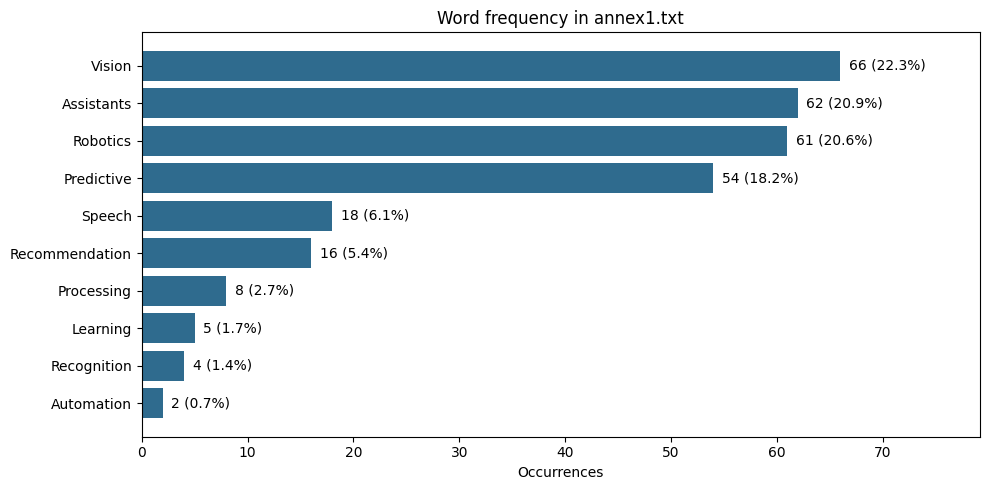

In [0]:
import matplotlib.pyplot as plt

# Retrieve word frequencies and calculate each word's percentage contribution to the total number of occurrences.
words = spark.sql("""
    SELECT word, word_count,
           ROUND(100.0 * word_count / SUM(word_count) OVER (), 1) AS pct
    FROM gold_word_counts
    ORDER BY word_count
""").toPandas()

# Create a horizontal bar chart to visualize word frequencies.
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(words["word"], words["word_count"], color="#2F6B8E")

ax.set_xlabel("Occurrences")
ax.set_title("Word frequency in annex1.txt")

# Display the count and percentage for each word next to its bar.
for bar, count, pct in zip(bars, words["word_count"], words["pct"]):
    ax.text(
        bar.get_width() + 0.8,
        bar.get_y() + bar.get_height() / 2,
        f"{count} ({pct}%)",
        va="center",
    )

# Add extra space on the x-axis to avoid clipping annotations.
ax.set_xlim(0, words["word_count"].max() * 1.2)

plt.tight_layout()
plt.show()


As shown in the dataset the most frequently occurring word is Vision, appearing 66 times and accounting for 22.3% of all occurrences. It is followed by Assistants with 62 occurrences and Robotics with 61. The least frequent word is Automation with 2 occurrences.

In [0]:
%sql
-- Hadoop verification results, and performance comparison
WITH word_statistics AS (

  -- Compute global statistics from the final word-count table
  SELECT
    SUM(word_count) AS total_words,
    COUNT(*) AS distinct_words,
    MAX_BY(word, word_count) AS most_frequent_word,
    MAX(word_count) AS most_frequent_count,
    MIN_BY(word, word_count) AS least_frequent_word,
    MIN(word_count) AS least_frequent_count
  FROM gold_word_counts

),
verification_summary AS (

  -- Count how many words produced identical result in both Spark and Hadoop implementations.
  SELECT
    SUM(
      CASE
        WHEN match = 'YES' THEN 1
        ELSE 0
      END
    ) AS matching_words,
    COUNT(*) AS compared_words
  FROM gold_hadoop_verification

),
execution_times AS (

  -- Retrieve the median execution time of both implementation
  SELECT
    MEDIAN(
      CASE
        WHEN variant = 'Hadoop end-to-end (time real)' THEN seconds
      END
    ) AS hadoop_median_time,
    MEDIAN(
      CASE
        WHEN variant = 'Spark end-to-end (Bronze-Silver-Gold)' THEN seconds
      END
    ) AS spark_median_time
  FROM gold_execution_times

)

-- Convert the summary into a key-value structure for easier presentation and reporting.
SELECT
-- Stack: Transforms summary statistics from columns into a two-column report.
  stack(
    6,
    'Total words',
    CAST(total_words AS STRING),

    'Distinct words',
    CAST(distinct_words AS STRING),

    'Most frequent word',
    CONCAT(most_frequent_word, ' (', most_frequent_count, ')'),

    'Least frequent word',
    CONCAT(least_frequent_word, ' (', least_frequent_count, ')'),

    'Words matching Hadoop',
    CONCAT(matching_words, ' of ', compared_words),

    'Speed-up (Hadoop time / Spark time)',
    CONCAT(ROUND(hadoop_median_time / spark_median_time, 1), 'x')

  ) AS (metric, value)
FROM
  word_statistics,
  verification_summary,
  execution_times;

metric,value
Total words,296
Distinct words,10
Most frequent word,Vision (66)
Least frequent word,Automation (2)
Words matching Hadoop,10 of 10
Speed-up (Hadoop time / Spark time),7.8x


*Spark measurement corresponds to the execution performed on November 10, 2026, at 5:18 PM*

- Same wourdcount result in both platforms. 10 of 10 words match and both totals are 296.
- The MapReduce model maps directly to Spark. The Map phase corresponds to the Silver laye and the Reduce phase corresponds to the Gold layer.
- The end-to-end median was 48.2 s in Hadoop versus 5.88 s in Spark (about 8 times faster). Hadoop's time was dominated by job start-up, separate YARN containers per task and task retries, Spark's by writing the Delta tables.
- The two runs used very different hardware: three small VirtualBox VMs with 1.75 GB of RAM per worker, against Databricks' serverless cloud compute with the Photon engine. In addition, the dataset is very small (296 words), so both engines spent most of their time on fixed costs, such as starting processes, scheduling tasks and writing results, rather than on actual data processing. Hadoop's times were also affected by task retries, most likely caused by the workers' limited memory.


## 10. References
Apache Software Foundation. (s.f.). MapReduce tutorial. Apache Hadoop. https://hadoop.apache.org/docs/stable/hadoop-mapreduce-client/hadoop-mapreduce-client-core/MapReduceTutorial.html

Databricks. (2026, September 11). Photon. Databricks Documentation. https://docs.databricks.com/aws/en/runtime/photon

Apache Spark. (s. f.). RDD Programming Guide. https://spark.apache.org/docs/latest/rdd-programming-guide.html